# Figure 2, Table 1, Extended Data Figures 2, 3 and 4

This notebook computes the figures related to results of Proof-of-Concept study.

In [1]:
import os
import re
import cv2
import sys
import json
import einops
import warnings
import itertools
import numpy as np
import pandas as pd
import pickle as pkl
import os.path as op
sys.path.append("..")
from tqdm import tqdm
from Bio.Seq import Seq
import Levenshtein as lev
from Bio import pairwise2
from itertools import product
from Bio import SeqIO, motifs
from itertools import product
import matplotlib.pyplot as plt
import src.swiper_cli as swiper
warnings.filterwarnings('ignore')
from matplotlib.patches import Patch
import src.convergence_test as convergence
from sklearn.metrics import matthews_corrcoef
from matplotlib.colors import LinearSegmentedColormap

/home/drlapki/micromamba/envs/ml-generic/lib/python3.9/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


### All required functions

In [2]:
def filter_results(r, lib="library1", setup="active", pool="complete_pool", n_round=10):
    """
    Filters the input dataframe r to include only rows matching the specified library, 
    setup, pool, and round number.

    Parameters
    ----------
        r (pandas.DataFrame): The input DataFrame to be filtered. 
        lib (str, optional): The library identifier. Defaults to 'library1'. 
        setup (str, optional): The setup identifier. Defaults to 'active'. 
        pool (str, optional): The pool identifier. Defaults to 'complete_pool'. 
        n_round (int, optional): The round number identifier. Defaults to 10.

    Returns
    -------
        pandas.DataFrame: The filtered DataFrame containing only the matching rows. 
    """
    b1 = r["setup"] == setup
    b2 = r["n_round"] == n_round
    b3 = r["library"] == lib
    b4 = r["pool"] == pool
    b = np.logical_and(
        np.logical_and(b1, b2),
        np.logical_and(b3, b4)
    )
    return(r.loc[b])


def learning_curve(F):
    """
    Processes the input DataFrame F to calculate summary statistics for the MCC metric across 
    different training set sizes.

    Groups the data by 'tts' and calculates the transformed training set size, mean MCC, 
    and standard deviation of MCC for each group.

    Parameters
    ----------
        F (pandas.DataFrame): The input DataFrame.

    Returns
    -------
        pandas.DataFrame: A DataFrame containing the computed metrics. 
    """
    F_ = {
        'Training set size': [], 'Mean MCC': [], 'Std MCC': []
    }
    for a in F.groupby("tts"):
        F_["Training set size"].append(float(a[0])*np.ceil(0.75*4**6))
        F_["Mean MCC"].append(np.mean(a[1]["mcc"]))
        F_["Std MCC"].append(np.std(a[1]["mcc"]))
    F_ = pd.DataFrame(F_)
    return(F_)

def pvalue_compute(mat):
    """
    Computes the p-values for the input matrix elements
    
    Parameters
    ----------
        mat (array_like): The input matrix.

    Returns
    -------
        numpy.ndarray: An array of computed p-values.
    """
    history_stat, history_H0, bvs, st, sigs = convergence.run_test(
        mat, (lefts, rights), convergence.statistic, pval_threshold=0.05
    )
    return(np.array([convergence.compute_pvalue(a, history_H0) for a in history_stat]))

def plot_learning_curve(ax, groups_df):
    """
    Plot a learning curve showing Mean MCC with confidence intervals
    
    Parameters
    ----------
    ax : matplotlib.axes.Axes
        The axes instance to plot on
    groups_df : DataFrame
        Must contain columns: 'Training set size', 'Mean MCC', 'Std MCC'
    """
    # Plot mean MCC line
    ax.plot(groups_df["Training set size"], groups_df["Mean MCC"], 
            color=(0,0,0,0.8))
    # Add confidence intervals
    ax.fill_between(
        groups_df["Training set size"], 
        groups_df["Mean MCC"]-groups_df["Std MCC"],
        groups_df["Mean MCC"]+groups_df["Std MCC"], 
        color=(0,0,0,0.4)
    )
    ax.fill_between(
        groups_df["Training set size"], 
        groups_df["Mean MCC"]-2*groups_df["Std MCC"],
        groups_df["Mean MCC"]+2*groups_df["Std MCC"], 
        color=(0,0,0,0.2)
    )
    # Customize plot
    ax.set_ylabel("MCC on hold-out set")
    ax.set_xlabel("Training set size")
    ax.set_ylim((-1,1))
    #ax.set_title("a", loc="left", weight="bold")
    # Create custom legend patches
    from matplotlib.patches import Patch
    ax.legend(
        loc="best",
        handles=[
            Patch(color=(0,0,0,0.8), label="Mean MCC"),
            Patch(color=(0,0,0,0.4), label="± Std MCC"),
            Patch(color=(0,0,0,0.2), label="± 2 Std MCC"),
        ]
    )
    # Add vertical lines
    ax.axvline(x=1260, ymin=-1, ymax=1, color="yellow", linestyle="dotted")
    ax.axvline(x=540, ymin=-1, ymax=1, color="yellow", linestyle="--")
    ax.axvline(x=18, ymin=-1, ymax=1, color="yellow", linestyle="-.")
    # Add annotations
    ax.annotate(
        text="One gel",
        xy=(18, -0.50),
        xytext=(60, -0.25),
        arrowprops={'arrowstyle': '->'},
        va='center'
    )
    ax.annotate(
        text="30 gels",
        xy=(540, -0.50),
        xytext=(600, -0.15),
        arrowprops={'arrowstyle': '->'},
        va='center'
    )
    ax.annotate(
        text="70 gels",
        xy=(1260, -0.50),
        xytext=(1400, -0.25),
        arrowprops={'arrowstyle': '->'},
        va='center'
    )
    
def plot_grouped_boxplot(ax, data_l1, data_l2, xtickslabels):
    """
    Create a grouped boxplot on the given Axes.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        The axes to draw on.
    data_l1 : list of array-like
        Data for the first library, one entry per group.
    data_l2 : list of array-like
        Data for the second library, one entry per group.
    xtickslabels : list of strings
        Ticks for the plot that represent query size.
    """
    n_groups = len(data_l1)
    pos_l1 = np.arange(1, n_groups + 1)
    pos_l2 = pos_l1 + 0.4  # shift right by 0.4 (original had 0.2, but 0.4 gives separation)
    bp1 = ax.boxplot(data_l1, positions=pos_l1, widths=0.2, patch_artist=True,
                     boxprops=dict(facecolor='black', color='yellow'),
                     medianprops=dict(color='yellow'),
                     whiskerprops=dict(color='yellow'),
                     capprops=dict(color='yellow'),
                     flierprops=dict(marker='o', markerfacecolor='yellow', alpha=0.5))

    bp2 = ax.boxplot(data_l2, positions=pos_l2, widths=0.2, patch_artist=True,
                     boxprops=dict(facecolor='yellow', color='black'),
                     medianprops=dict(color='black'),
                     whiskerprops=dict(color='black'),
                     capprops=dict(color='black'),
                     flierprops=dict(marker='o', markerfacecolor='black', alpha=0.5))

    # Center ticks between the two groups and label them
    ax.set_xticks(pos_l1 + 0.2)
    #ax.set_xticklabels([str(i) for i in range(1, n_groups + 1)])
    ax.set_xticklabels(xtickslabels)
    ax.set_ylabel("MCC")
    ax.set_xlabel("Query size")
    ax.legend([bp1["boxes"][0], bp2["boxes"][0]], ["Library 1", "Library 2"])
    
def plot_violins(
    ax, passive_mean, passive_std, A_C, A_G, R_C, R_G, passive=True, NPOS=11, 
    legend=True, what="active_mcc", scale=True
):
    """
    Plot violin plots for different learning strategies and data pools.

    Parameters
    ----------
        ax (matplotlib.axes.Axes): The axes object to plot on.
        passive_mean (float): Mean MCC value for the passive baseline.
        passive_std (float): Standard deviation for the passive baseline.
        A_C (pandas.DataFrame): Data for Active Learning, complete pool.
        A_G (pandas.DataFrame): Data for Active Learning, golden set.
        R_G (pandas.DataFrame): Data for Random choice, golden set.
        R_C (pandas.DataFrame): Data for Random choice, complete pool.
        passive (bool): If True, draw background shading for passive mean.
        NPOS (int): Number of positions.
        legend (bool): If True, display the legend.
        what (str): The key to extract from the dataframe.
        scale (bool): If True, set y-axis limits to (-1, 1).
        
    Returns
    -------
        None
    """
    if passive:
        ax.fill_between(
            np.arange(1,11), 
            [passive_mean-passive_std]*10,
            [passive_mean+passive_std]*10, 
            color=(0,0,0,0.4)
        )
        ax.fill_between(
            np.arange(1,11), 
            [passive_mean-2*passive_std]*10,
            [passive_mean+2*passive_std]*10, 
            color=(0,0,0,0.2)
        )
        ax.plot(
            np.arange(1,11), 
            [passive_mean]*10, color="black"
        )
    # Create positions for each group to separate them horizontally
    positions = np.arange(1, NPOS)
    # Offset positions for each of the 4 groups
    offset = 0.2  # Adjust this value to control separation
    pos_A_C = positions - 1.5*offset
    pos_A_G = positions - 0.5*offset
    pos_R_G = positions + 0.5*offset
    pos_R_C = positions + 1.5*offset
    violin_color = 'black'
    vp1 = ax.violinplot(
        [a[1][what] for a in A_C.groupby("n_round")], positions=pos_A_C, 
        showmeans=False, showmedians=True, showextrema=False, widths=0.35
    )
    for pc in vp1['bodies']:
        pc.set_facecolor(violin_color)
        pc.set_alpha(1)
        pc.set_edgecolor('black')
    vp1['cmedians'].set_color('yellow')
    vp1['cmedians'].set_linewidth(2)
    violin_color = 'yellow'
    vp2 = ax.violinplot([a[1][what] for a in A_G.groupby("n_round")], positions=pos_A_G, 
                        showmeans=False, showmedians=True, showextrema=False, widths=0.35)
    for pc in vp2['bodies']:
        pc.set_facecolor(violin_color)
        pc.set_alpha(1)
        pc.set_edgecolor('black')
    vp2['cmedians'].set_color('black')
    vp2['cmedians'].set_linewidth(2)
    violin_color = 'gainsboro'
    vp3 = ax.violinplot([a[1][what] for a in R_G.groupby("n_round")], positions=pos_R_G, 
                        showmeans=False, showmedians=True, showextrema=False, widths=0.35)
    for pc in vp3['bodies']:
        pc.set_facecolor(violin_color)
        pc.set_alpha(1)
        pc.set_edgecolor('black')
    vp3['cmedians'].set_color('black')
    vp3['cmedians'].set_linewidth(2)
    violin_color = 'snow'
    vp4 = ax.violinplot([a[1][what] for a in R_C.groupby("n_round")], positions=pos_R_C, 
                        showmeans=False, showmedians=True, showextrema=False, widths=0.35)
    for pc in vp4['bodies']:
        pc.set_facecolor(violin_color)
        pc.set_alpha(1)
        pc.set_edgecolor('black')
    vp4['cmedians'].set_color('black')
    vp4['cmedians'].set_linewidth(2)
    # Set x-ticks to be at the original positions (1 through 10)
    ax.set_xticks(ticks=positions)
    if legend:
        ax.legend(
            loc="lower right",
            handles=[
                Patch(color=(0,0,0,0.8), label="Mean MCC (PL, all orthologs)"),
                Patch(color=(0,0,0,0.4), label="± Std MCC (PL, all orthologs)"),
                Patch(color=(0,0,0,0.2), label="± 2 Std MCC (PL, all orthologs)"),
                Patch(color="black", label="Active Learning, complete pool"),
                Patch(color="yellow", label="Active Learning, golden set"),
                Patch(color="snow", label="Random choice, complete pool"),
                Patch(color="gainsboro", label="Random choice, golden set"),
            ]
        )
    if scale:
        ax.set_ylim((-1,1))
    ax.set_ylabel("MCC on hold-out set")
    ax.set_xlabel("#Rounds")
    
    
def EDF3_legend(ax, loc="lower right"):
    """
    Adds a Extended Data Figure 3 legend to the provided axes object.

    This function places a legend on the axes with predefined labels for
    Active Learning and Random choice strategies (complete pool and golden set).

    Parameters
    ----------
        ax: The matplotlib axes instance to which the legend will be added.
        loc (str, optional): The location of the legend on the axes. Defaults
            to 'lower right'.

    Returns
    -------
        None
    """
    ax.legend(
        loc=loc,
        handles=[
            Patch(color="black", label="Active Learning, complete pool"),
            Patch(color="yellow", label="Active Learning, golden set"),
            Patch(color="snow", label="Random choice, complete pool"),
            Patch(color="gainsboro", label="Random choice, golden set"),
        ]
    )
    ax.set_ylabel("Consensus score")
    ax.set_xlabel("#Gels")

def EDF4_legend(ax, loc="lower right"):
    """
    Adds a Extended Data Figure 4 legend to the provided axes object.

    This function places a legend on the axes with predefined labels for
    Active Learning and Random choice strategies (complete pool and golden set).

    Parameters
    ----------
        ax: The matplotlib axes instance to which the legend will be added.
        loc (str, optional): The location of the legend on the axes. Defaults
            to 'lower right'.

    Returns
    -------
        None
    """
    ax.legend(
        loc=loc,
        handles=[
            Patch(color="black", label="Active Learning, complete pool"),
            Patch(color="yellow", label="Active Learning, golden set"),
            Patch(color="snow", label="Random choice, complete pool"),
            Patch(color="gainsboro", label="Random choice, golden set"),
            Patch(color="red", label="p=0.05"),
        ]
    )
    ax.set_ylabel("P-values")
    ax.set_xlabel("#Gel pairs")
    
def cumulative_proportion(df, lbl, N=10, threshold=0.05):
    """
    Calculates the cumulative proportion of simulations where the condition
    (value < threshold) was met before specific round numbers.

    Parameters
    ----------
        df: The input DataFrame containing 'value', 'seed', and 'n_round' columns.
        lbl: The label for the resulting row index.
        N: The total number of simulations.
        threshold: The threshold value for the condition.

    Returns
    -------
        A pandas DataFrame with columns 'before #3', 'before #5', 'before #7',
        'before #10', 'after #10 or never' containing the calculated proportions.
    """
    sigs = df[df["value"] < threshold].groupby("seed")
    cnts = list(zip(*np.unique([a[1]["n_round"].min() for a in sigs], return_counts=True)))
    cnts = pd.DataFrame(np.array(cnts))
    output = pd.DataFrame(
        {
            "before #3": [np.sum(cnts[1][cnts[0] < 3])/N],
            "before #5": [np.sum(cnts[1][cnts[0] < 5])/N],
            "before #7": [np.sum(cnts[1][cnts[0] < 7])/N],
            "before #10": [np.sum(cnts[1][cnts[0] < 10])/N],
            "after #10 or never": [1-np.sum(cnts[1][cnts[0] < 10])/N]
        }
    )
    output.index = [lbl]
    return(output)

def cumulative_proportion_detailed(df, lbl, N=10, threshold=0.05):
    """
    Calculates the proportion of simulations where the condition (value < threshold) was met at specific round numbers.

    Parameters
    ----------
        df (pandas.DataFrame): The input DataFrame containing 'value', 'seed', and 'n_round' columns.
        lbl: The label for the resulting row index.
        N (int): The total number of simulations.
        threshold (float): The threshold value for the condition.

    Returns
    -------
        pandas.DataFrame: A DataFrame with columns 1 through 10. The index corresponds to `lbl`.
    """
    sigs = df[df["value"] < threshold].groupby("seed")
    cnts = list(zip(*np.unique([a[1]["n_round"].min() for a in sigs], return_counts=True)))
    cnts = pd.DataFrame(np.array(cnts))
    output = pd.DataFrame(
        {a: [np.sum(cnts[1][cnts[0] == a])/N] for a in np.arange(1,11)}
    )
    output.index = [lbl]
    return(output)


def make_proper_df(lst):
    """
    Converts the input list `lst` into a pandas DataFrame formatted for analysis.

    Parameters
    ----------
        lst: The input list or matrix.

    Returns
    -------
        A pandas DataFrame with columns 'value', 'seed', and 'n_round'.
    """
    return(
        pd.DataFrame(
            {
                "value": einops.rearrange(lst, "seed pair -> (seed pair)"),
                "seed": seed_pair.T[0], "n_round": seed_pair.T[1]
            }
        )
    )

### Load all data

In [3]:
F2a = pd.read_csv("../data/processed/F2a.tsv", sep="\t", index_col=0)
F2a_l1 = F2a[F2a["library"] == "library1"]
F2a_l2 = F2a[F2a["library"] == "library2"]
F2a_l1_mean = learning_curve(F2a_l1)
F2a_l2_mean = learning_curve(F2a_l2)
F2b_l1 = filter_results(pd.read_csv("../data/processed/F2bcdef.tsv", sep="\t", index_col=0))
F2b_l2 = filter_results(pd.read_csv("../data/processed/F2bcdef.tsv", sep="\t", index_col=0), lib="library2")
F2 = pd.read_csv("../data/processed/F2/18.tsv", sep="\t", index_col=0)
F2_l1 = F2[np.logical_and(F2["library"] == "library2", F2["n_queries"] == 18)]
F2_l2 = F2[np.logical_and(F2["library"] == "library2", F2["n_queries"] == 18)]
q_l1 = {a[0]:a[1] for a in F2b_l1.groupby("n_queries")}
q_l2 = {a[0]:a[1] for a in F2b_l2.groupby("n_queries")}
data_l1 = [q_l1[a]["active_mcc"] for a in q_l1]
data_l2 = [q_l2[a]["active_mcc"] for a in q_l2]
with open("../data/processed/consensi.json", "r") as ih:
    consensi = json.loads(ih.read())
perfect_scores = {a: {b: convergence.consensus_score(consensi[a][b], consensi[a][b]) for b in consensi[a]} for a in consensi}
F2_l1["max_normalized_score"] = F2_l1["score"]/F2_l1["ortholog"].apply(lambda x: perfect_scores["library2"][x.replace("_", " ")+" PPDV"])
F2_l2["max_normalized_score"] = F2_l2["score"]/F2_l2["ortholog"].apply(lambda x: perfect_scores["library2"][x.replace("_", " ")+" PPDV"])
F2l1_AC = F2_l1.loc[np.logical_and(F2_l1["pool"] == "complete_pool", F2_l1["setup"] == "active")]
F2l1_RC = F2_l1.loc[np.logical_and(F2_l1["pool"] == "complete_pool", F2_l1["setup"] == "random")]
F2l1_AG = F2_l1.loc[np.logical_and(F2_l1["pool"] == "golden_set", F2_l1["setup"] == "active")]
F2l1_RG = F2_l1.loc[np.logical_and(F2_l1["pool"] == "golden_set", F2_l1["setup"] == "random")]
F2l2_AC = F2_l2.loc[np.logical_and(F2_l2["pool"] == "complete_pool", F2_l2["setup"] == "active")]
F2l2_RC = F2_l2.loc[np.logical_and(F2_l2["pool"] == "complete_pool", F2_l2["setup"] == "random")]
F2l2_AG = F2_l2.loc[np.logical_and(F2_l2["pool"] == "golden_set", F2_l2["setup"] == "active")]
F2l2_RG = F2_l2.loc[np.logical_and(F2_l2["pool"] == "golden_set", F2_l2["setup"] == "random")]
grp = {a[0]: a[1] for a in F2l2_AC.groupby("seed")}

In [4]:
F2d = F2_l1[
    np.logical_and(F2_l1["setup"] == "active", 
                   np.logical_not(np.isin(F2_l1["pool"], ["complete_pool", "golden_set", "1", "10"])))
]
F2d["pool"] = F2d["pool"].apply(int)
F2d["n_round"] = F2d["n_round"].apply(int)
F2d_tensor = []
for a in F2d.groupby("ortholog"):
    F2d_tensor.append(
        [[c[1].max_normalized_score.values for c in b[1].groupby("n_round")] for b in a[1].groupby("pool")]
    )
F2d_tensor = np.array(F2d_tensor)
F2d_tensor_reduced = einops.reduce(F2d_tensor, "ortholog pool n_round seed -> pool n_round", "mean")

Compute H0 samples for statistical tests

In [5]:
lefts = convergence.generate_H0(10000, lags=[1,2,3,4,5], alphabet=convergence.IUPAC_DNA_no_gap)
rights = convergence.make_rights(lefts, alphabet=convergence.IUPAC_DNA_no_gap)

In [6]:
F2d_tensor = []
for a in F2d.groupby("ortholog"):
    F2d_tensor.append(
        [[c[1].max_normalized_score.values for c in b[1].groupby("n_round")] for b in a[1].groupby("pool")]
    )

In [7]:
F2_l1_pv = F2_l1[np.isin(F2_l1.pool, ["complete_pool", "golden_set"])]
pvalues = {}
for a in tqdm(F2_l1_pv.groupby("ortholog")):
    pvalues[a[0]] = {b[0]: {c[0]: {d[0]: pvalue_compute(d[1][["pam", "score"]].values.astype(str)) for d in c[1].groupby("pool")} for c in b[1].groupby("setup")} for b in a[1].groupby("seed")}

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 9/9 [00:28<00:00,  3.15s/it]


## Figure 2

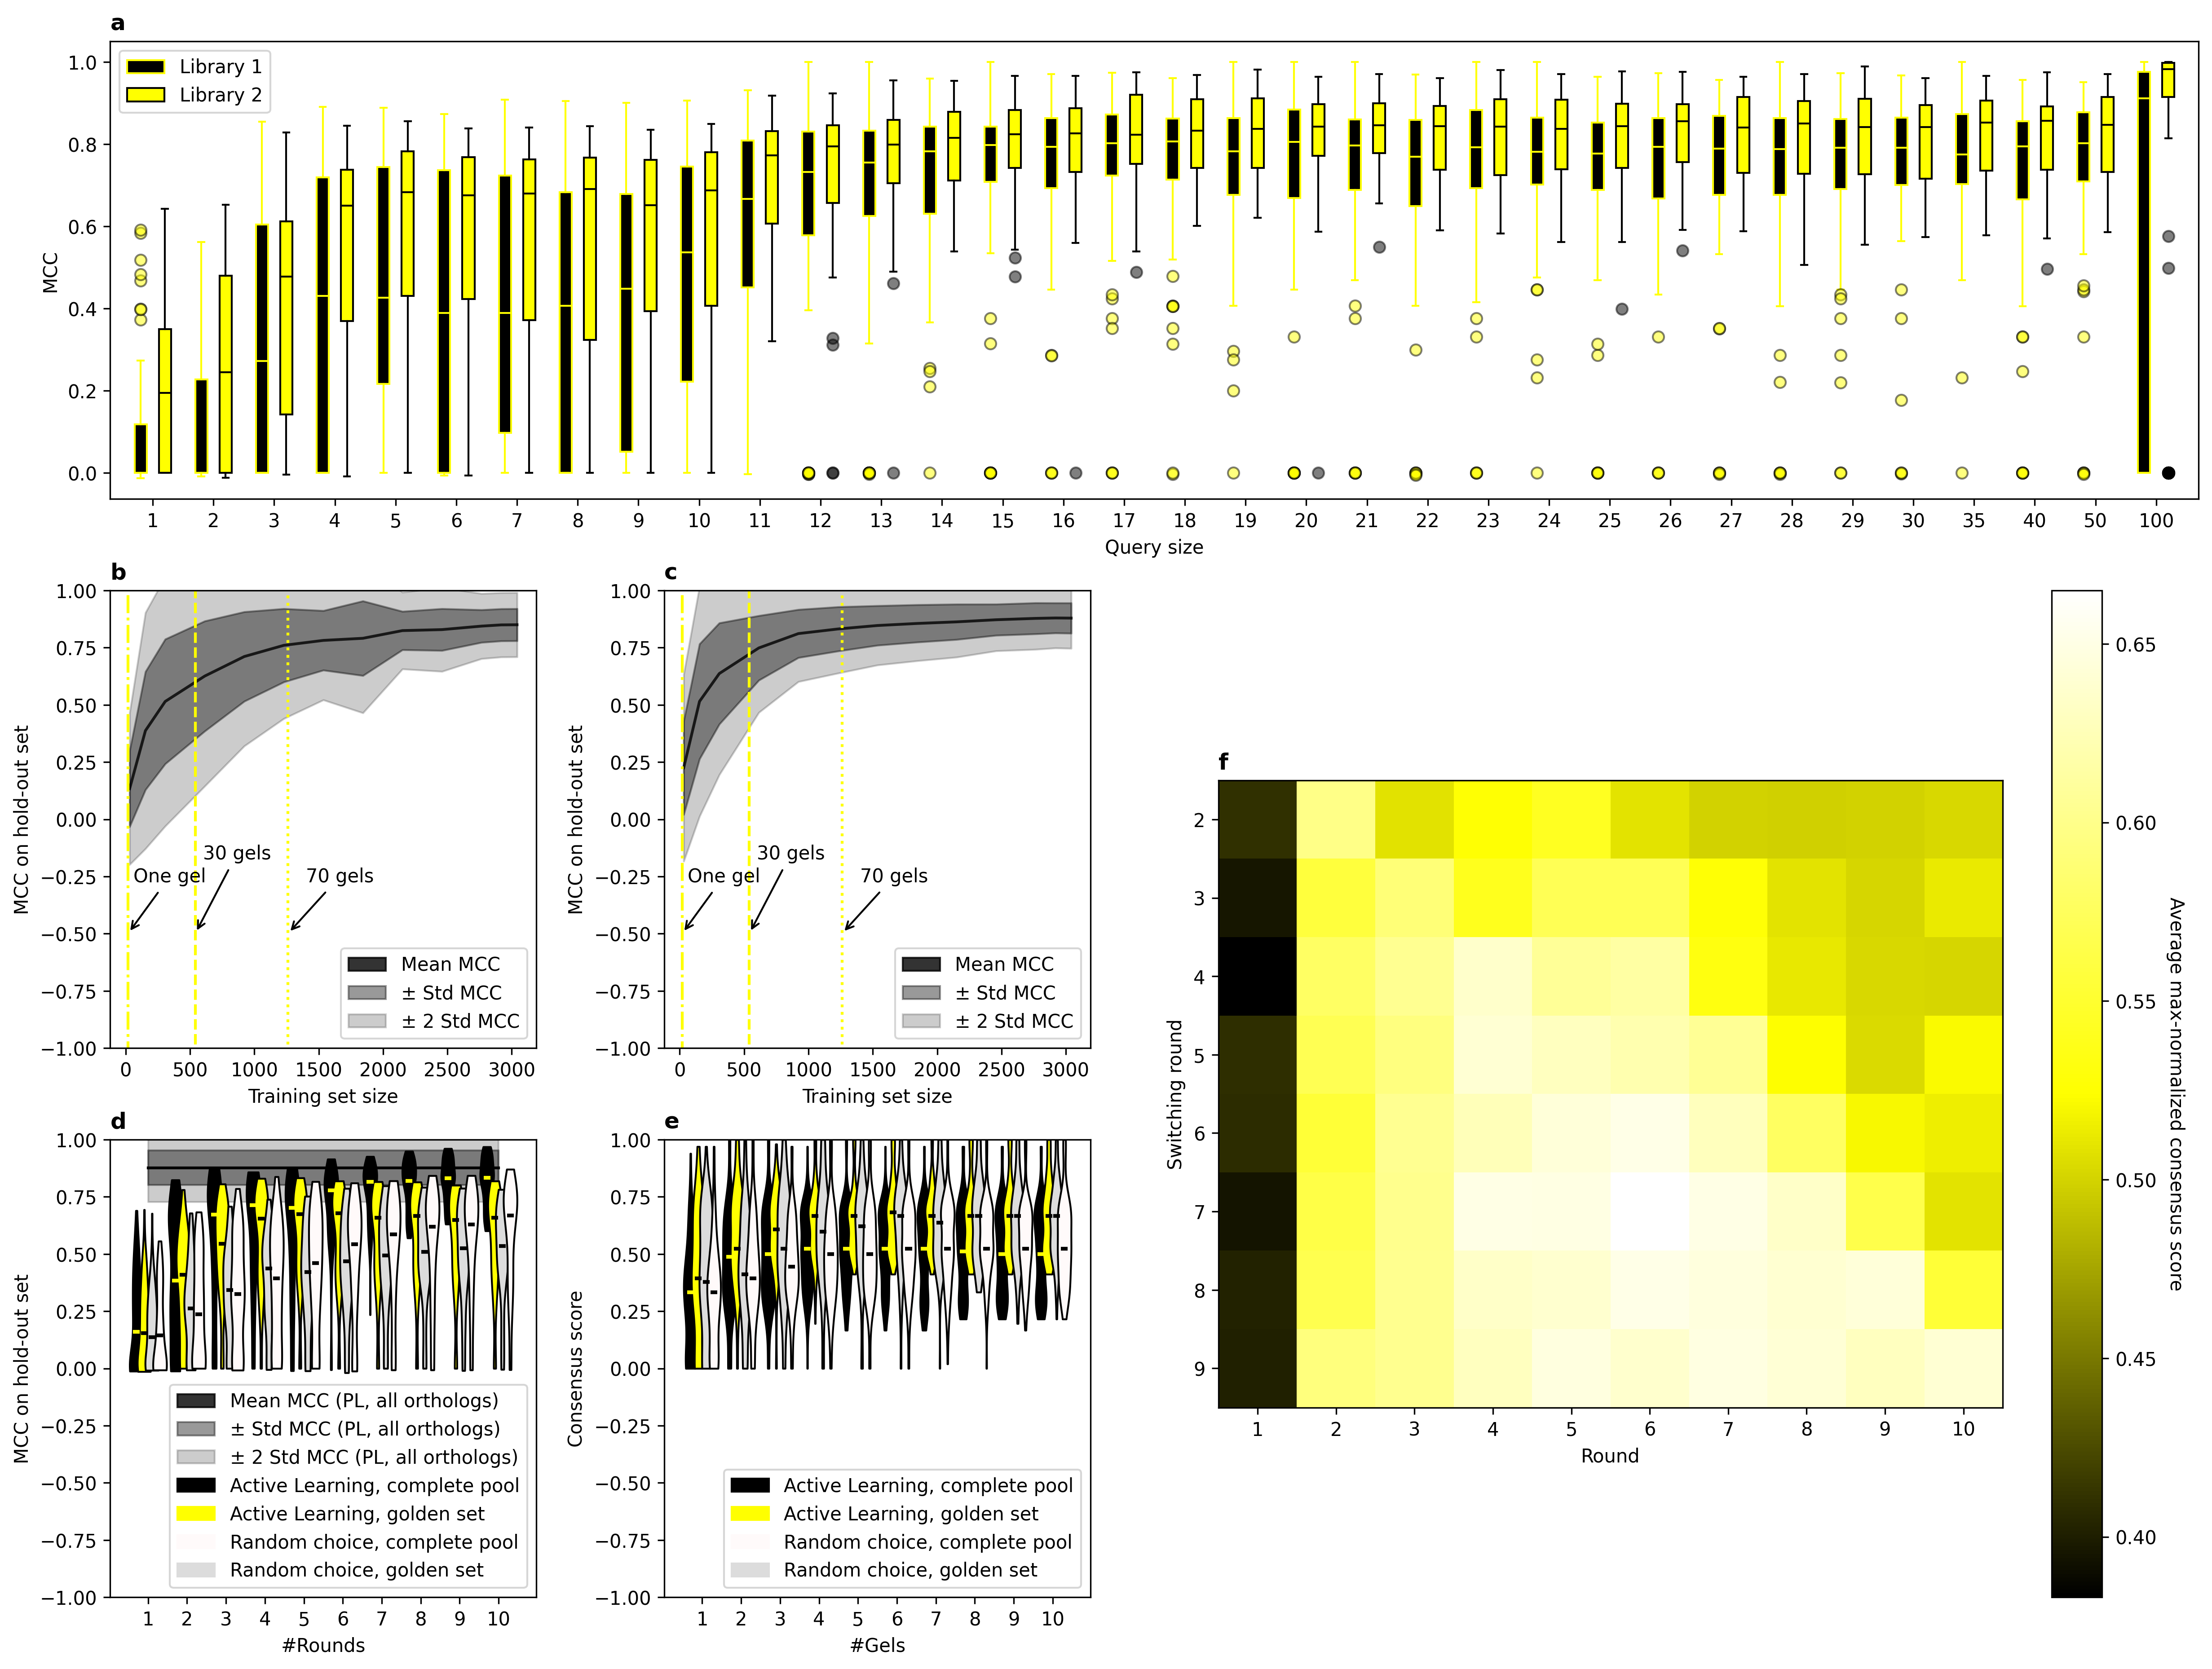

In [8]:
plt.rcParams["figure.figsize"] = 20, 15
plt.rcParams["figure.dpi"] = 300

fig = plt.figure()
axd = fig.subplot_mosaic(
    """
    AAAA
    BCFF
    DEFF
    """
)

axd["A"].set_title("a", loc="left", weight="bold")
axd["B"].set_title("b", loc="left", weight="bold")
axd["C"].set_title("c", loc="left", weight="bold")
axd["D"].set_title("d", loc="left", weight="bold")
axd["E"].set_title("e", loc="left", weight="bold")
axd["F"].set_title("f", loc="left", weight="bold")

plot_grouped_boxplot(axd["A"], data_l1, data_l2, xtickslabels=[str(a) for a in q_l1.keys()])
plot_learning_curve(axd["B"], F2a_l1_mean)
plot_learning_curve(axd["C"], F2a_l2_mean)
plot_violins(
    axd["D"], F2l1_AC["passive_mcc"].mean(), F2l1_AC["passive_mcc"].std(), F2l1_AC, F2l1_AG, F2l1_RC, F2l1_RG, NPOS=11
)
plot_violins(
    axd["E"], F2l1_AC["max_normalized_score"].mean(), F2l1_AC["max_normalized_score"].std(), F2l1_AC, F2l1_AG, F2l1_RC, F2l1_RG, NPOS=11, 
    passive=False, what="max_normalized_score", legend=False
)
axd["E"].set_ylabel("Max normalized score")
EDF3_legend(axd["E"])

# Define colors at key points
colors = [(0, 0, 0),      # Black at 0
          (1, 1, 0),      # Yellow at 0.5
          (1, 1, 1)]      # White at 1
# Create colormap
cmap = LinearSegmentedColormap.from_list('black_yellow_white', colors)


axd["F"].set_xticks(np.arange(0,10), np.arange(1,11))
axd["F"].set_yticks(np.arange(0,10), np.arange(2,12))
im = axd["F"].imshow(F2d_tensor_reduced, cmap=cmap)
axd["F"].set_xlabel("Round")
axd["F"].set_ylabel("Switching round")

cbar = fig.colorbar(im, ax=axd["F"])
cbar.set_label('Average max-normalized consensus score', rotation=270, labelpad=15)  # Customize label if needed

plt.subplots_adjust(wspace=0.3)
plt.savefig("Figure2.png", bbox_inches='tight', pad_inches=0)

plt.show()

## Extended Data Figure 2

In [9]:
orthologs = F2l1_AC.ortholog.unique()

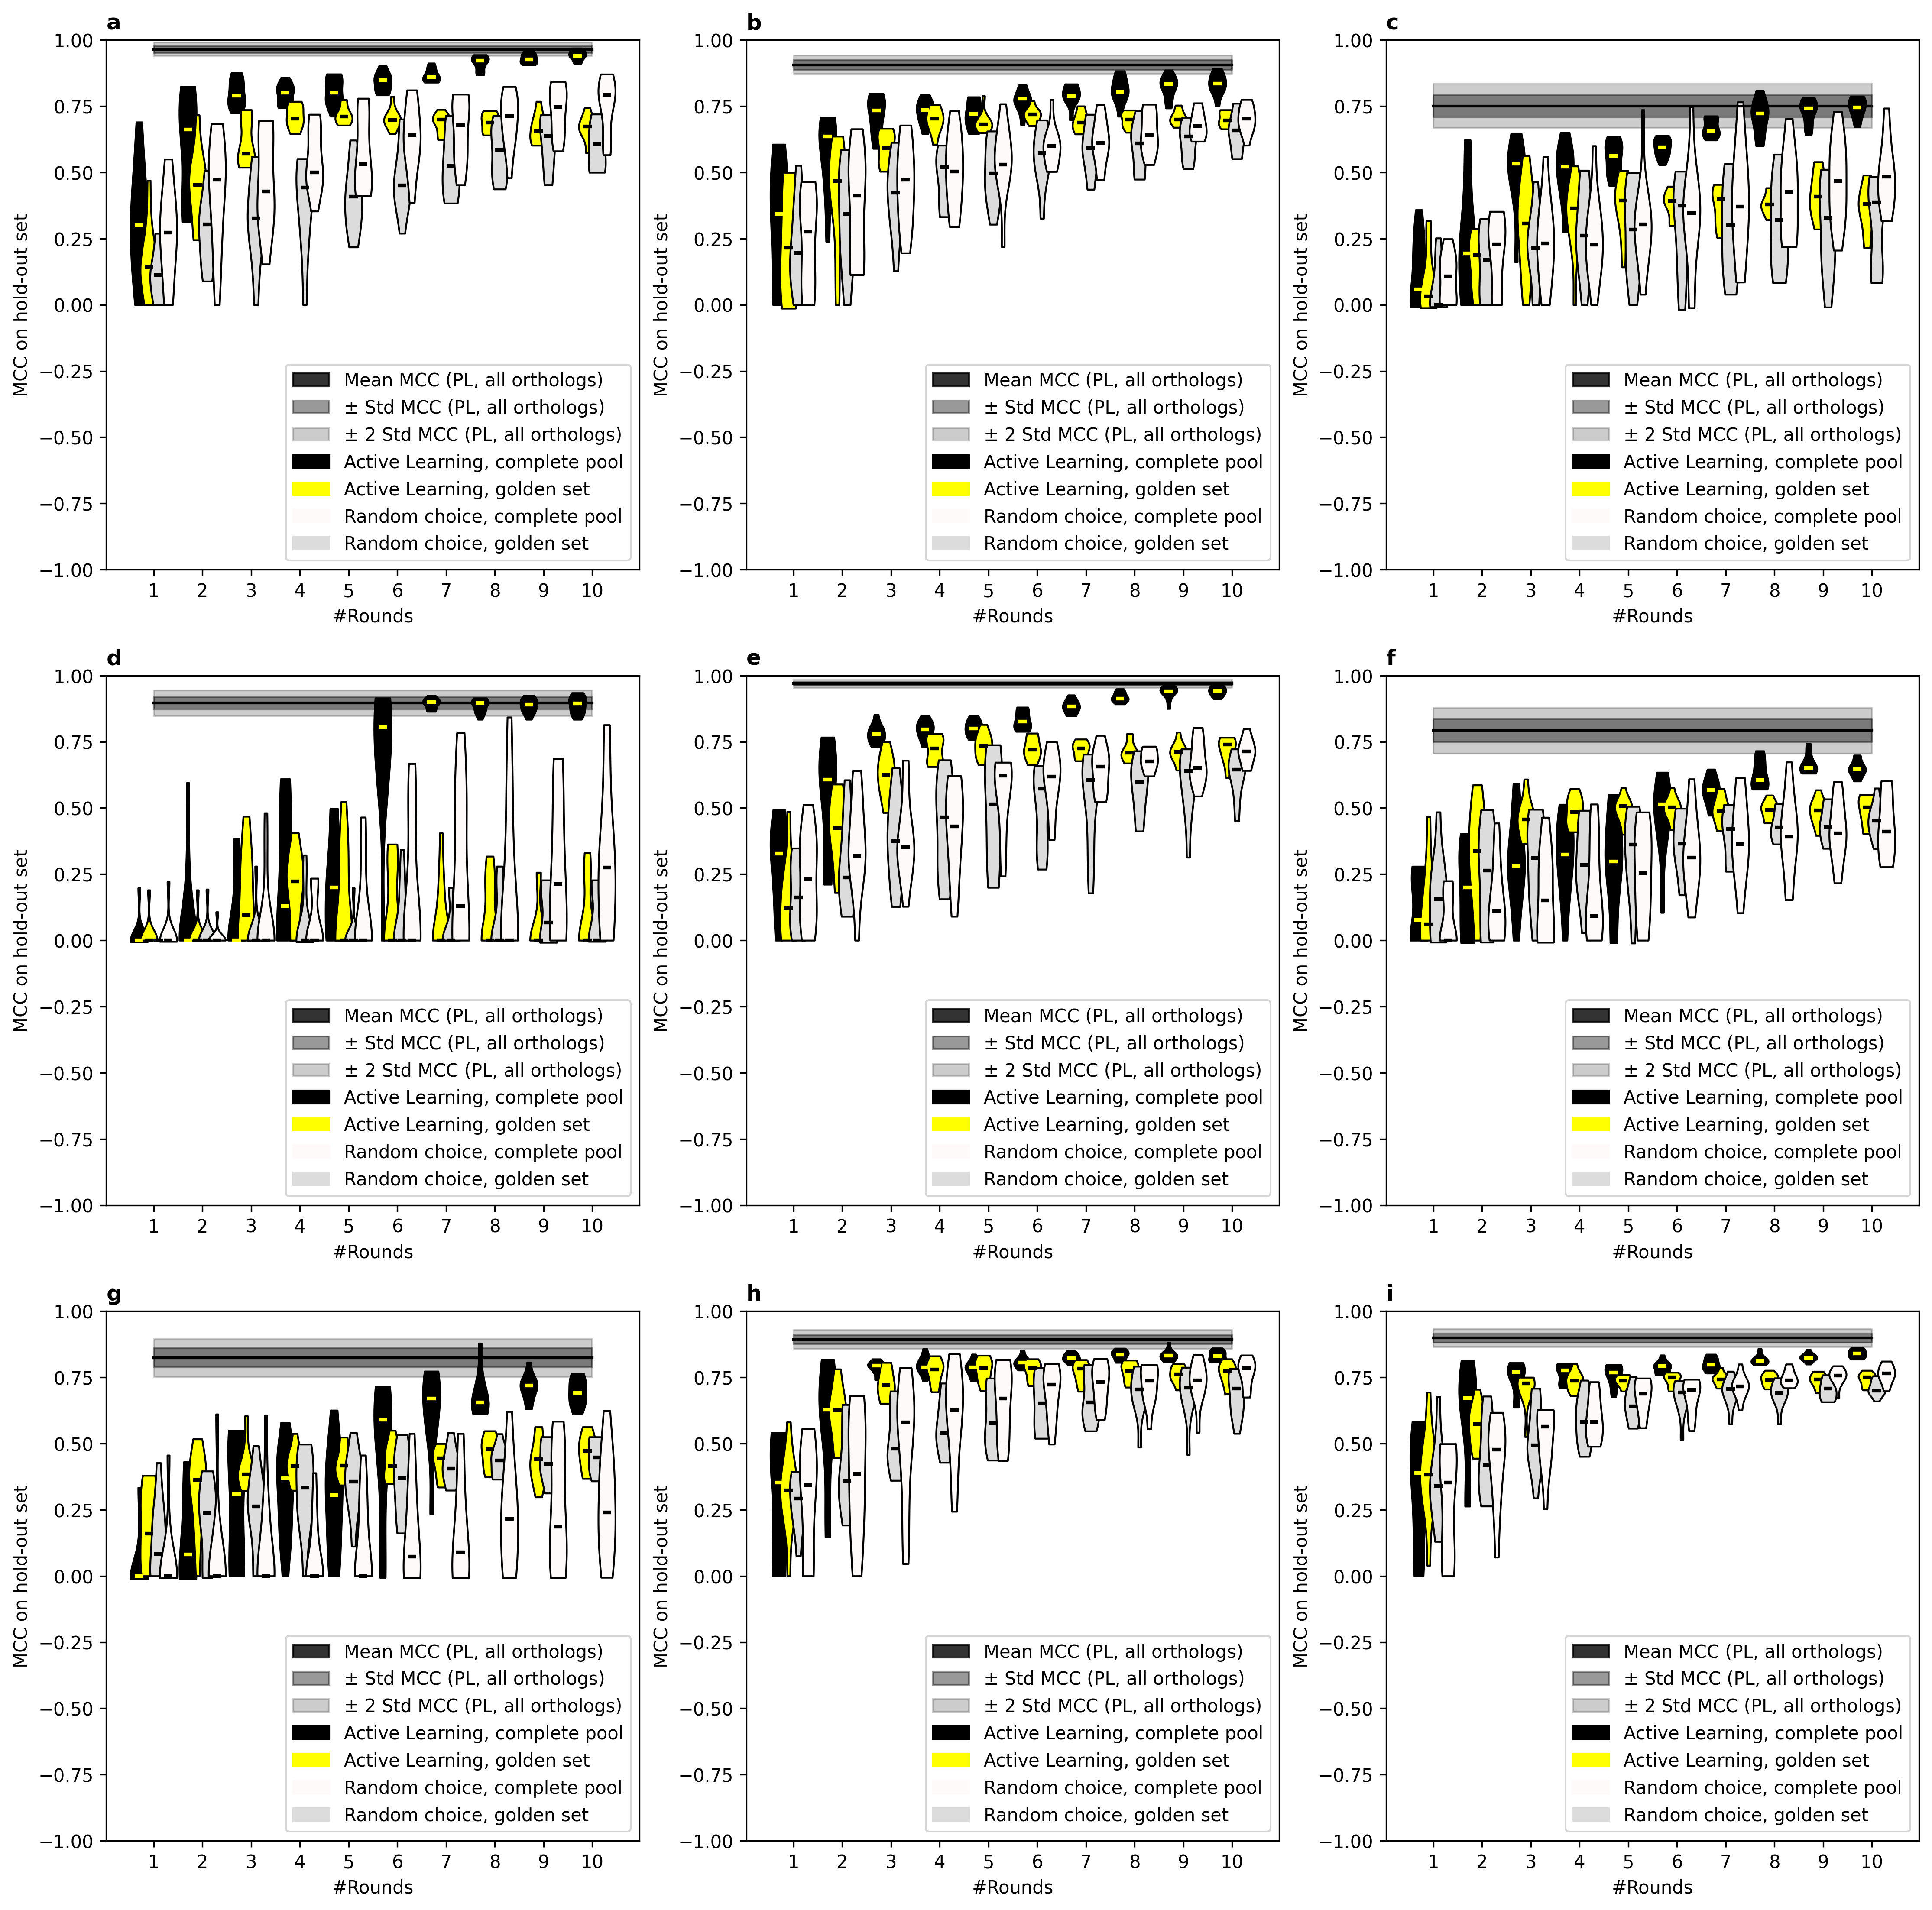

In [10]:
plt.rcParams["figure.figsize"] = 18, 18
plt.rcParams["figure.dpi"] = 300

fig = plt.figure()
axd = fig.subplot_mosaic(
    """
    ABC
    DEF
    GHI
    """
)


axd["A"].set_title("a", loc="left", weight="bold")
plot_violins(
    axd["A"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[0]]["passive_mcc"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[0]]["passive_mcc"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[0]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[0]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[0]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[0]], NPOS=11
)


axd["B"].set_title("b", loc="left", weight="bold")
plot_violins(
    axd["B"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[1]]["passive_mcc"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[1]]["passive_mcc"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[1]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[1]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[1]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[1]], NPOS=11
)

axd["C"].set_title("c", loc="left", weight="bold")
plot_violins(
    axd["C"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[2]]["passive_mcc"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[2]]["passive_mcc"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[2]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[2]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[2]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[2]], NPOS=11
)

axd["D"].set_title("d", loc="left", weight="bold")
plot_violins(
    axd["D"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[3]]["passive_mcc"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[3]]["passive_mcc"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[3]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[3]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[3]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[3]], NPOS=11
)

axd["E"].set_title("e", loc="left", weight="bold")
plot_violins(
    axd["E"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[4]]["passive_mcc"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[4]]["passive_mcc"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[4]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[4]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[4]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[4]], NPOS=11
)

axd["F"].set_title("f", loc="left", weight="bold")
plot_violins(
    axd["F"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[5]]["passive_mcc"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[5]]["passive_mcc"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[5]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[5]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[5]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[5]], NPOS=11
)

axd["G"].set_title("g", loc="left", weight="bold")
plot_violins(
    axd["G"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[6]]["passive_mcc"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[6]]["passive_mcc"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[6]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[6]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[6]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[6]], NPOS=11
)

axd["H"].set_title("h", loc="left", weight="bold")
plot_violins(
    axd["H"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[7]]["passive_mcc"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[7]]["passive_mcc"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[7]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[7]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[7]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[7]], NPOS=11
)

axd["I"].set_title("i", loc="left", weight="bold")
plot_violins(
    axd["I"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[8]]["passive_mcc"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[8]]["passive_mcc"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[8]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[8]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[8]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[8]], NPOS=11
)


plt.savefig("EDF2.png", bbox_inches='tight', pad_inches=0)

plt.show()

## Extended Data Figure 3

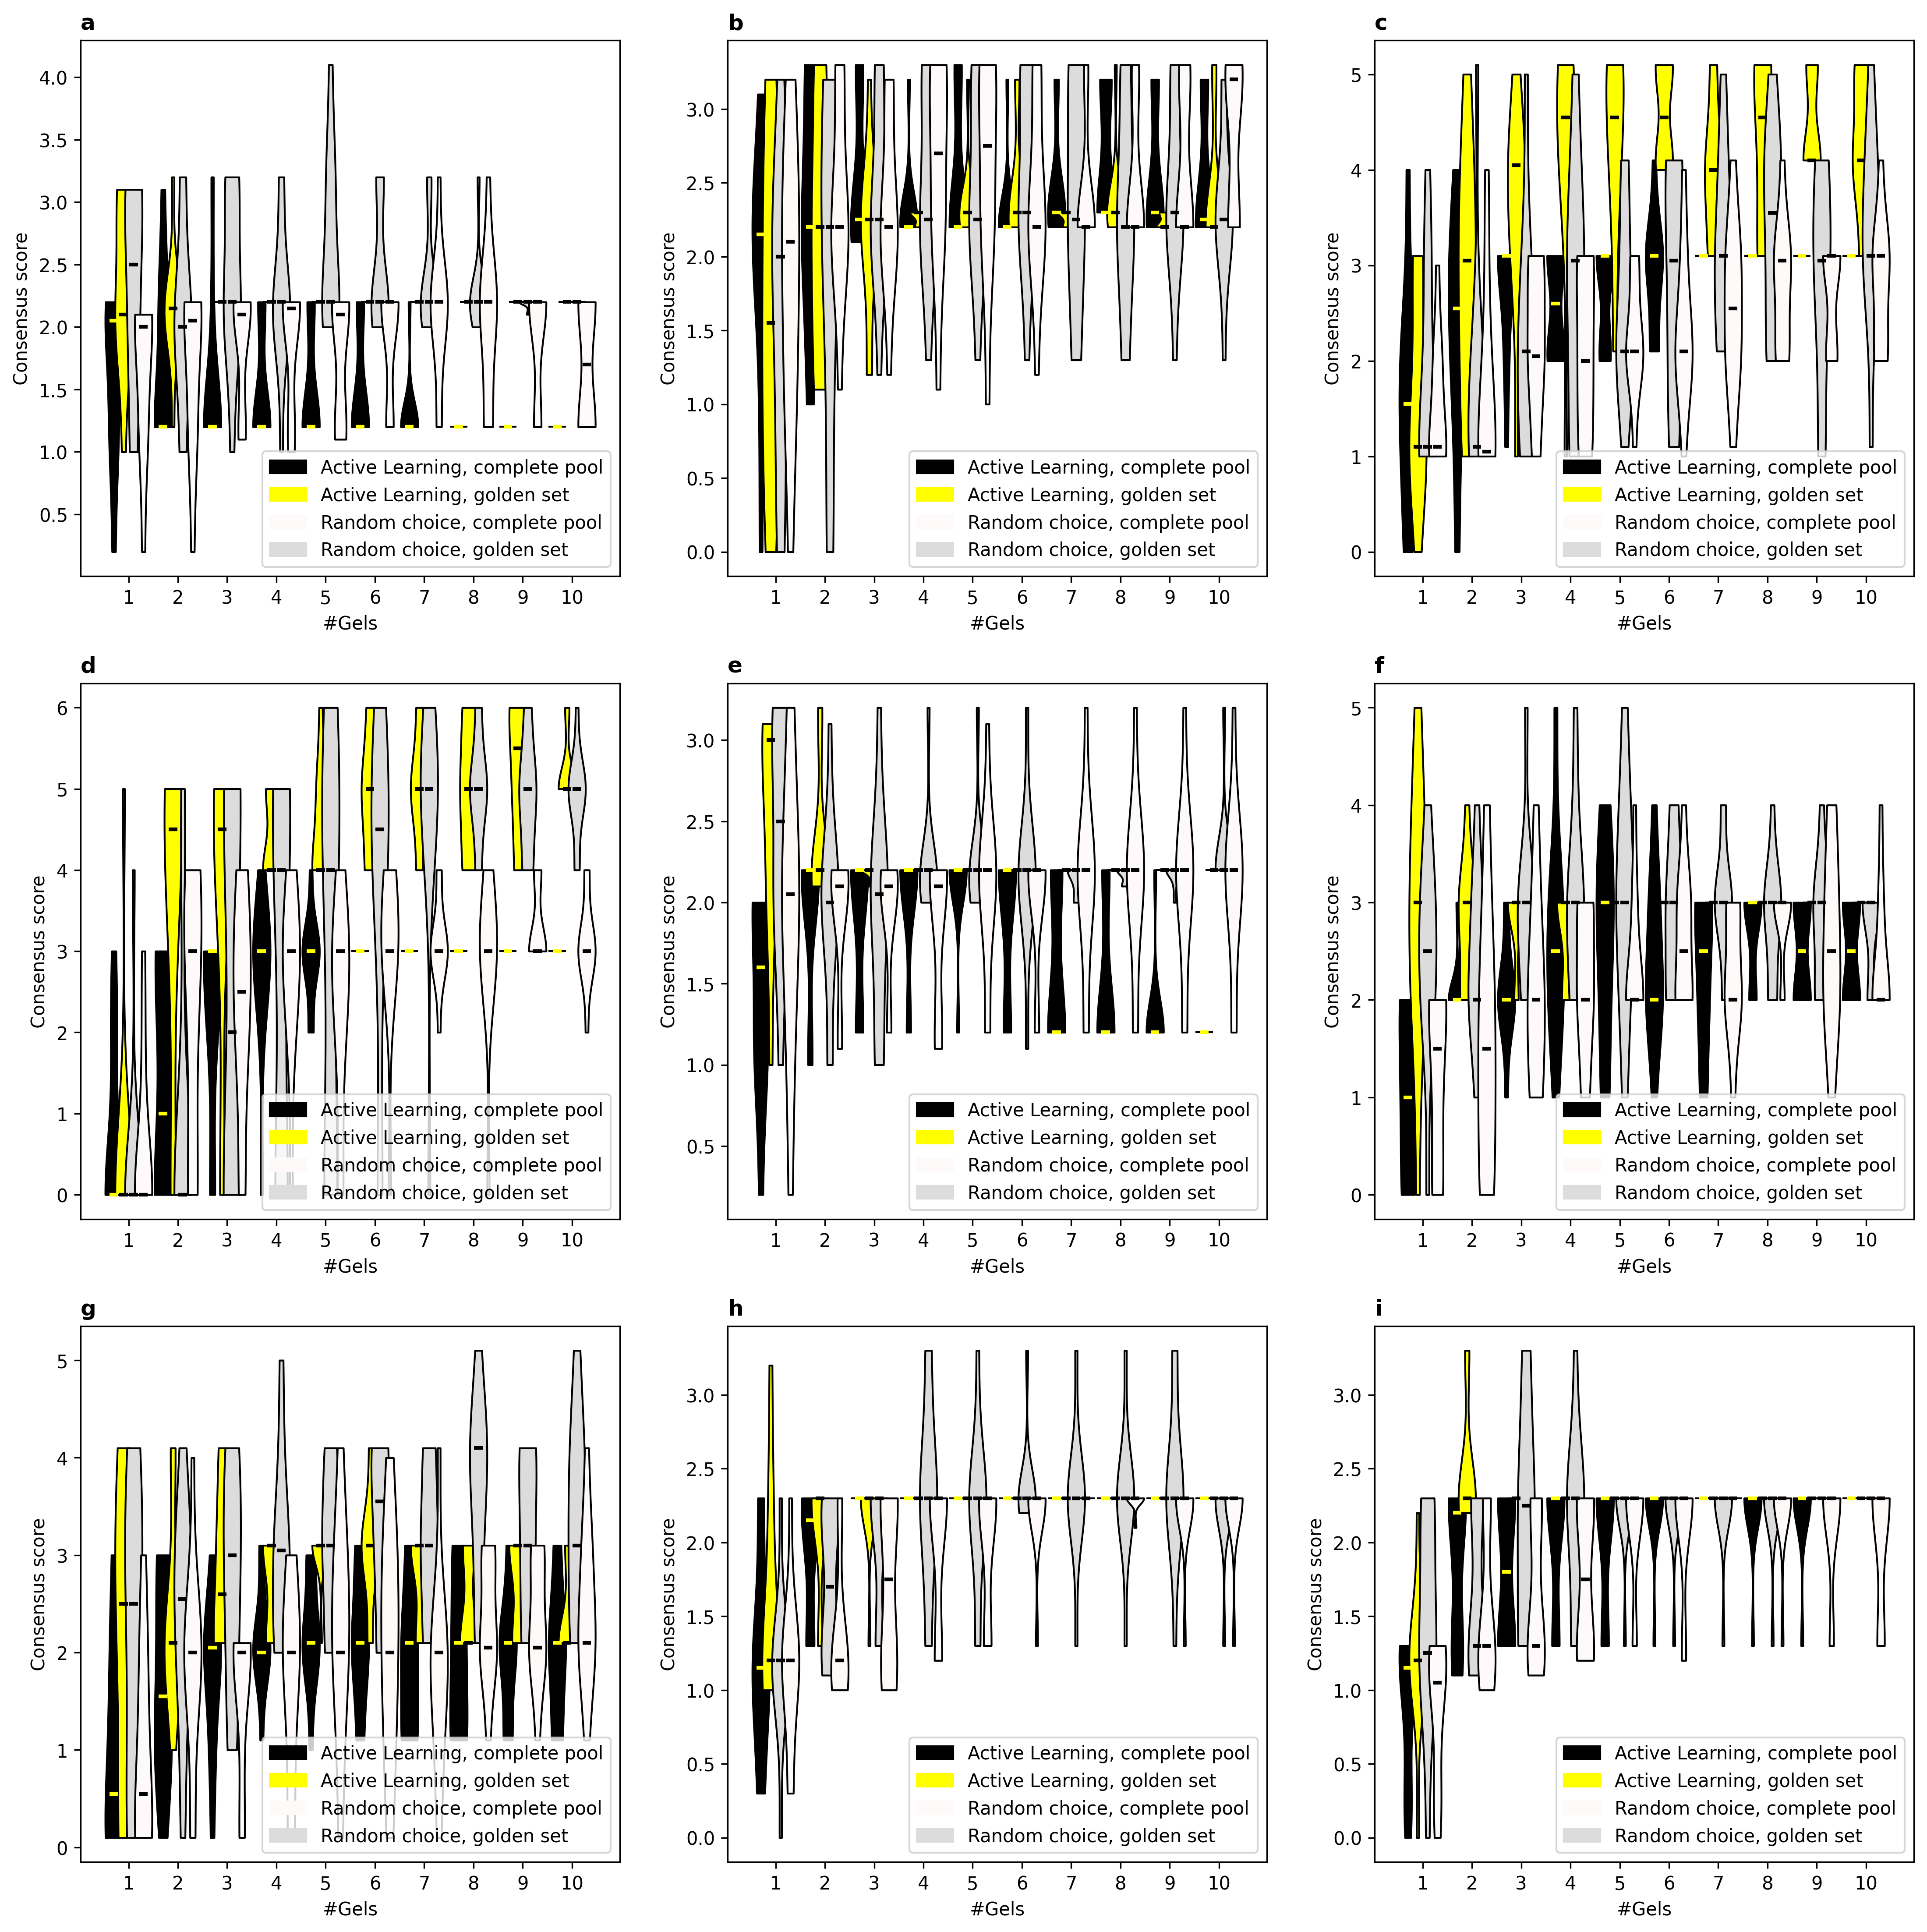

In [11]:
plt.rcParams["figure.figsize"] = 18, 18
plt.rcParams["figure.dpi"] = 300

fig = plt.figure()
axd = fig.subplot_mosaic(
    """
    ABC
    DEF
    GHI
    """
)


axd["A"].set_title("a", loc="left", weight="bold")
plot_violins(
    axd["A"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[0]]["score"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[0]]["score"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[0]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[0]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[0]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[0]], 
    NPOS=11, what="score", legend=False, passive=False, scale=False
)
axd["A"].set_ylabel("Consensus score")
EDF3_legend(axd["A"])


axd["B"].set_title("b", loc="left", weight="bold")
plot_violins(
    axd["B"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[1]]["score"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[1]]["score"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[1]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[1]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[1]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[1]], 
    NPOS=11, what="score", legend=False, passive=False, scale=False
)
axd["B"].set_ylabel("Consensus score")
EDF3_legend(axd["B"])

axd["C"].set_title("c", loc="left", weight="bold")
plot_violins(
    axd["C"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[2]]["score"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[2]]["score"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[2]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[2]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[2]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[2]], 
    NPOS=11, what="score", legend=False, passive=False, scale=False
)
axd["C"].set_ylabel("Consensus score")
EDF3_legend(axd["C"])

axd["D"].set_title("d", loc="left", weight="bold")
plot_violins(
    axd["D"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[3]]["score"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[3]]["score"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[3]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[3]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[3]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[3]], 
    NPOS=11, what="score", legend=False, passive=False, scale=False
)
axd["D"].set_ylabel("Consensus score")
EDF3_legend(axd["D"])

axd["E"].set_title("e", loc="left", weight="bold")
plot_violins(
    axd["E"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[4]]["score"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[4]]["score"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[4]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[4]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[4]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[4]], 
    NPOS=11, what="score", legend=False, passive=False, scale=False
)
axd["E"].set_ylabel("Consensus score")
EDF3_legend(axd["E"])

axd["F"].set_title("f", loc="left", weight="bold")
plot_violins(
    axd["F"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[5]]["score"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[5]]["score"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[5]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[5]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[5]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[5]], 
    NPOS=11, what="score", legend=False, passive=False, scale=False
)
axd["F"].set_ylabel("Consensus score")
EDF3_legend(axd["F"])

axd["G"].set_title("g", loc="left", weight="bold")
plot_violins(
    axd["G"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[6]]["score"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[6]]["score"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[6]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[6]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[6]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[6]], 
    NPOS=11, what="score", legend=False, passive=False, scale=False
)
axd["G"].set_ylabel("Consensus score")
EDF3_legend(axd["G"])

axd["H"].set_title("h", loc="left", weight="bold")
plot_violins(
    axd["H"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[7]]["score"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[7]]["score"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[7]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[7]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[7]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[7]],
    NPOS=11, what="score", legend=False, passive=False, scale=False
)
axd["H"].set_ylabel("Consensus score")
EDF3_legend(axd["H"])

axd["I"].set_title("i", loc="left", weight="bold")
plot_violins(
    axd["I"], F2l1_AC[F2l1_AC["ortholog"] == orthologs[8]]["score"].mean(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[8]]["score"].std(), 
    F2l1_AC[F2l1_AC["ortholog"] == orthologs[8]], F2l1_AG[F2l1_AG["ortholog"] == orthologs[8]], 
    F2l1_RC[F2l1_RC["ortholog"] == orthologs[8]], F2l1_RG[F2l1_RG["ortholog"] == orthologs[8]], 
    NPOS=11, what="score", legend=False, passive=False, scale=False
)
axd["I"].set_ylabel("Consensus score")
EDF3_legend(axd["I"])


plt.savefig("EDF3.png", bbox_inches='tight', pad_inches=0)

plt.show()

In [12]:
seed_pair = np.array(list(itertools.product(np.arange(1,11), np.arange(1,10))))

In [13]:
pvals_AC = {b: make_proper_df(np.array([pvalues[b][a]["active"]["complete_pool"] for a in np.arange(1,11)])) for b in orthologs}
pvals_AG = {b: make_proper_df(np.array([pvalues[b][a]["active"]["golden_set"] for a in np.arange(1,11)])) for b in orthologs}
pvals_RC = {b: make_proper_df(np.array([pvalues[b][a]["random"]["complete_pool"] for a in np.arange(1,11)])) for b in orthologs}
pvals_RG = {b: make_proper_df(np.array([pvalues[b][a]["random"]["golden_set"] for a in np.arange(1,11)])) for b in orthologs}

## Extended Data Figure 4

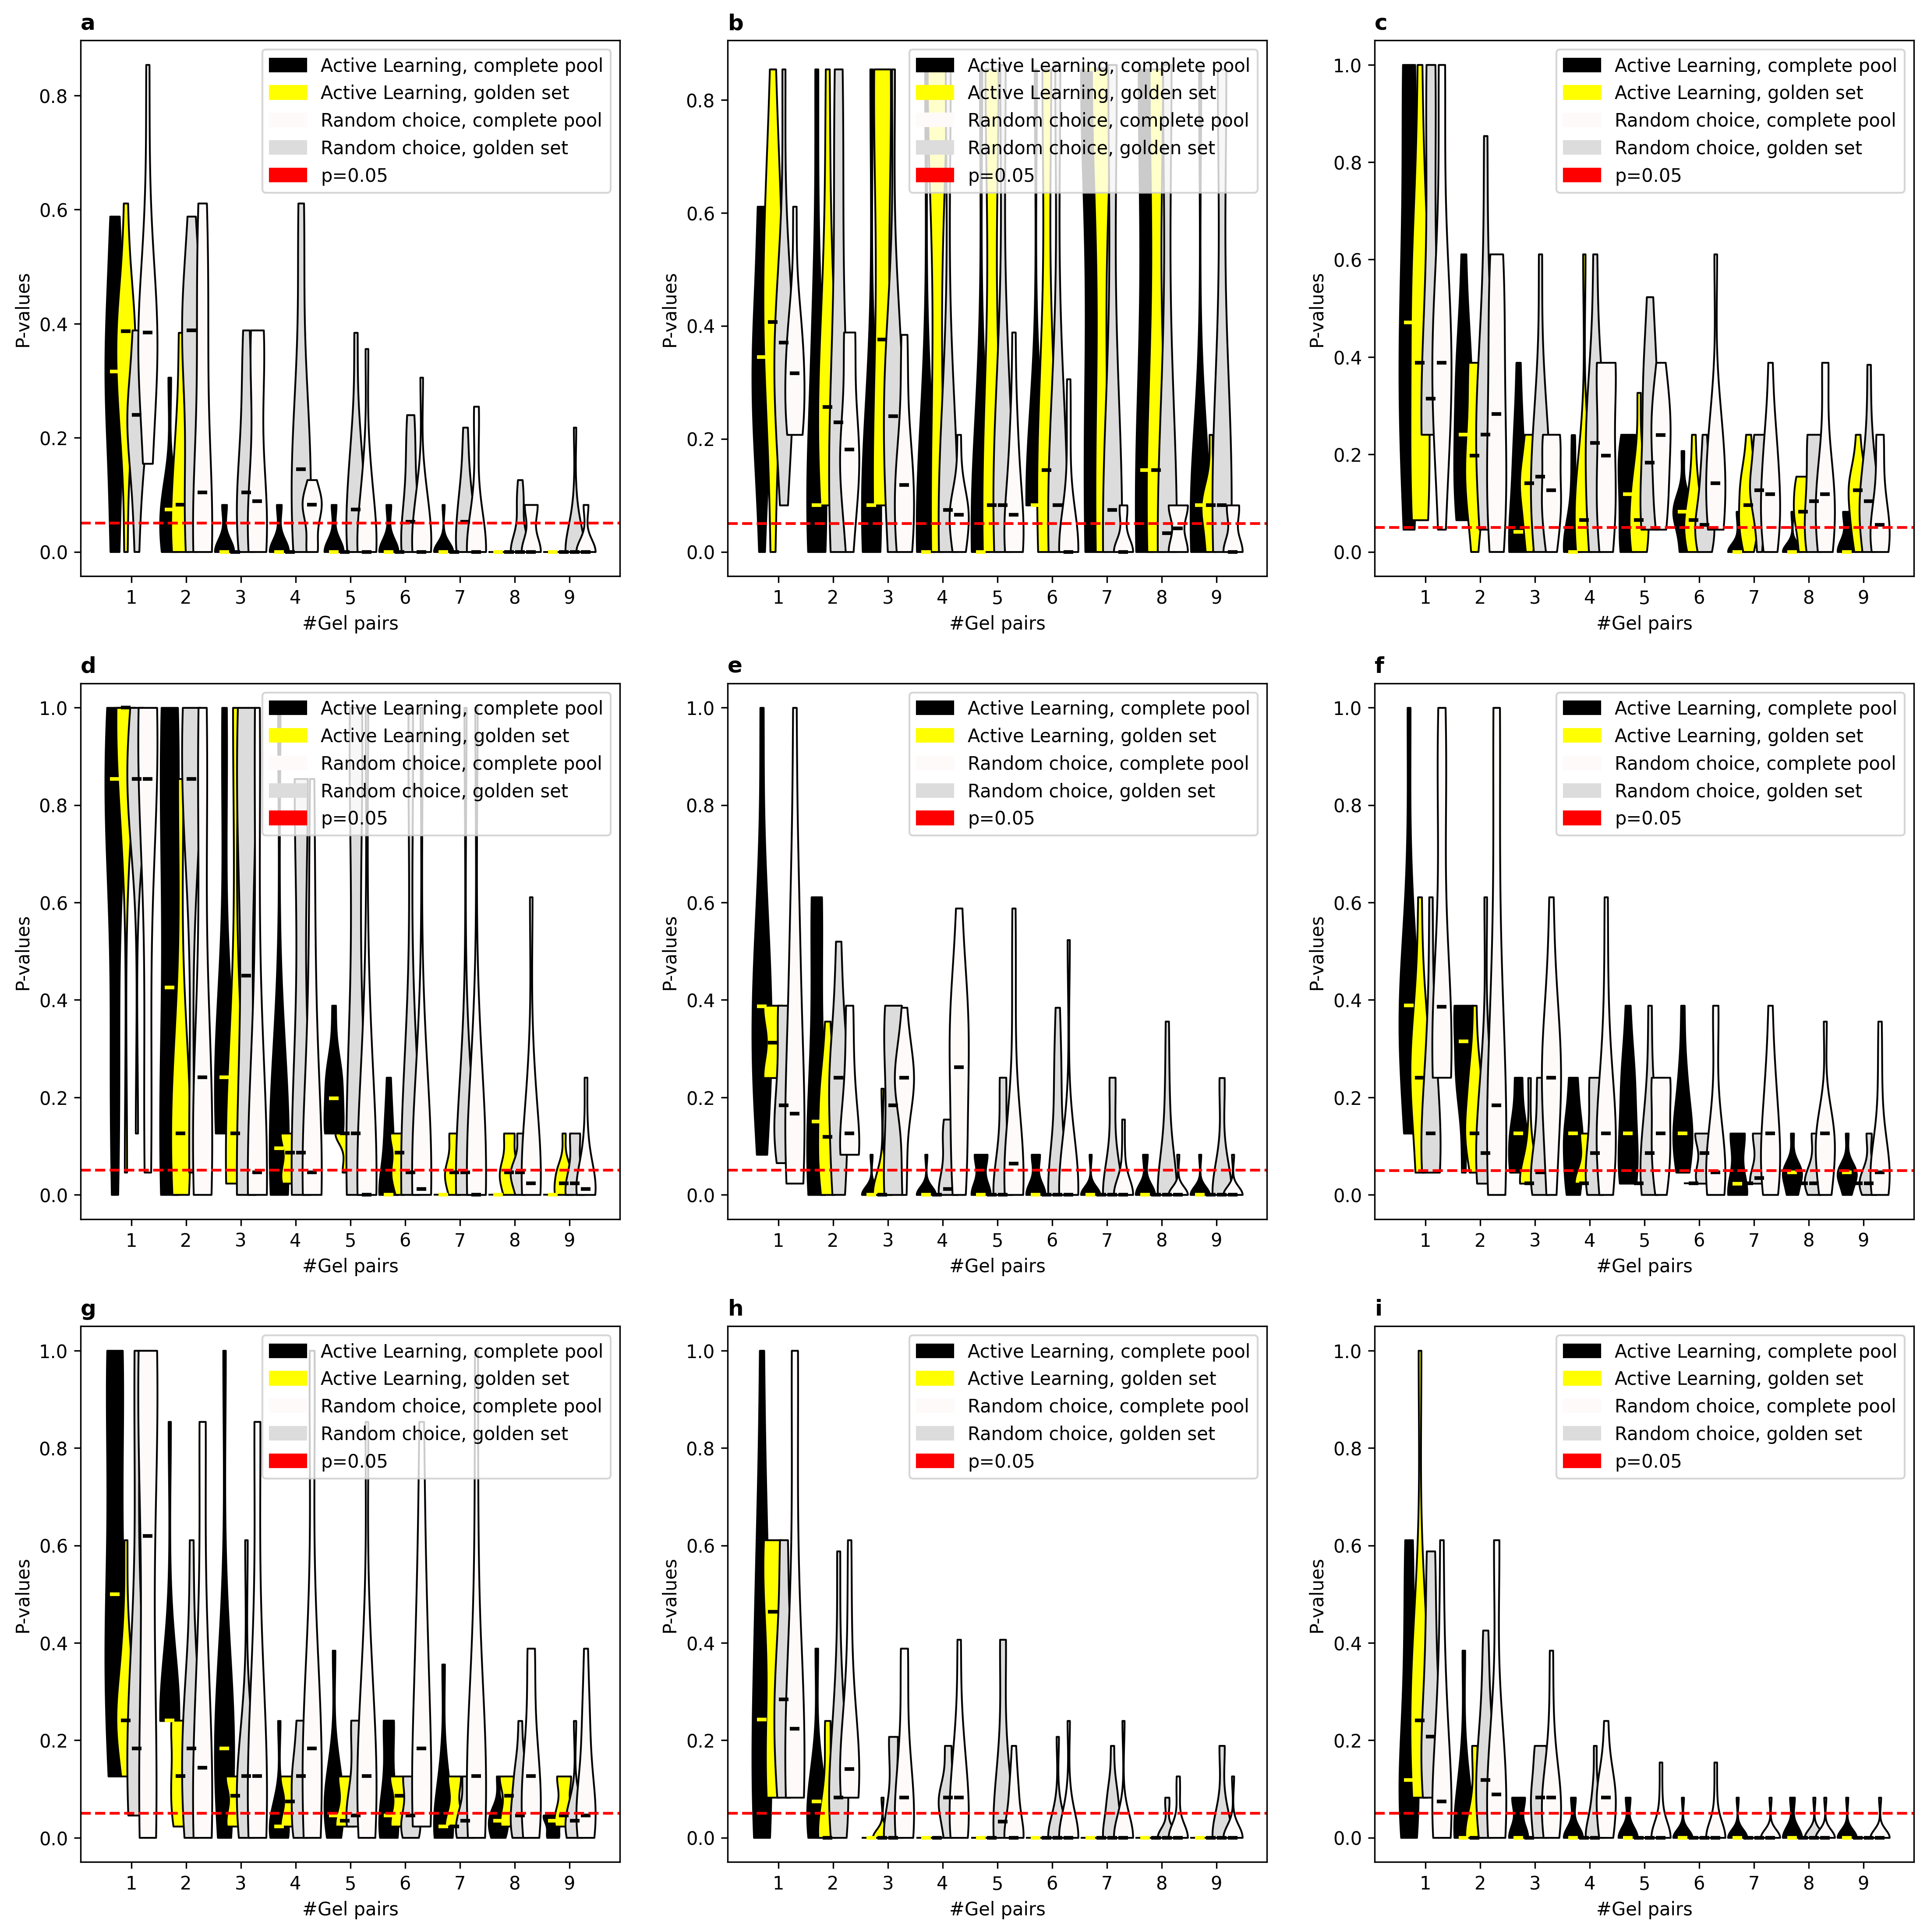

In [14]:
plt.rcParams["figure.figsize"] = 18, 18
plt.rcParams["figure.dpi"] = 300

fig = plt.figure()
axd = fig.subplot_mosaic(
    """
    ABC
    DEF
    GHI
    """
)


axd["A"].set_title("a", loc="left", weight="bold")
plot_violins(
    axd["A"], 0, 
    0, 
    pvals_AC[orthologs[0]], 
    pvals_AG[orthologs[0]], 
    pvals_RC[orthologs[0]], 
    pvals_RG[orthologs[0]], 
    NPOS=10, what="value", legend=False, passive=False, scale=False
)
axd["A"].set_ylabel("P-value")
axd["A"].axhline(y=0.05, color="red", linestyle="dashed")
EDF4_legend(axd["A"], loc="upper right")

axd["B"].set_title("b", loc="left", weight="bold")
plot_violins(
    axd["B"], 0, 
    0, 
    pvals_AC[orthologs[1]], 
    pvals_AG[orthologs[1]], 
    pvals_RC[orthologs[1]], 
    pvals_RG[orthologs[1]], 
    NPOS=10, what="value", legend=False, passive=False, scale=False
)
axd["B"].set_ylabel("P-value")
axd["B"].axhline(y=0.05, color="red", linestyle="dashed")
EDF4_legend(axd["B"], loc="upper right")

axd["C"].set_title("c", loc="left", weight="bold")
plot_violins(
    axd["C"], 0, 
    0, 
    pvals_AC[orthologs[2]], 
    pvals_AG[orthologs[2]], 
    pvals_RC[orthologs[2]], 
    pvals_RG[orthologs[2]], 
    NPOS=10, what="value", legend=False, passive=False, scale=False
)
axd["C"].set_ylabel("P-value")
axd["C"].axhline(y=0.05, color="red", linestyle="dashed")
EDF4_legend(axd["C"], loc="upper right")

axd["D"].set_title("d", loc="left", weight="bold")
plot_violins(
    axd["D"], 0, 
    0, 
    pvals_AC[orthologs[3]], 
    pvals_AG[orthologs[3]], 
    pvals_RC[orthologs[3]], 
    pvals_RG[orthologs[3]], 
    NPOS=10, what="value", legend=False, passive=False, scale=False
)
axd["D"].set_ylabel("P-value")
axd["D"].axhline(y=0.05, color="red", linestyle="dashed")
EDF4_legend(axd["D"], loc="upper right")

axd["E"].set_title("e", loc="left", weight="bold")
plot_violins(
    axd["E"], 0, 
    0, 
    pvals_AC[orthologs[4]], 
    pvals_AG[orthologs[4]], 
    pvals_RC[orthologs[4]], 
    pvals_RG[orthologs[4]], 
    NPOS=10, what="value", legend=False, passive=False, scale=False
)
axd["E"].set_ylabel("P-value")
axd["E"].axhline(y=0.05, color="red", linestyle="dashed")
EDF4_legend(axd["E"], loc="upper right")

axd["F"].set_title("f", loc="left", weight="bold")
plot_violins(
    axd["F"], 0, 
    0, 
    pvals_AC[orthologs[5]], 
    pvals_AG[orthologs[5]], 
    pvals_RC[orthologs[5]], 
    pvals_RG[orthologs[5]], 
    NPOS=10, what="value", legend=False, passive=False, scale=False
)
axd["F"].set_ylabel("P-value")
axd["F"].axhline(y=0.05, color="red", linestyle="dashed")
EDF4_legend(axd["F"], loc="upper right")

axd["G"].set_title("g", loc="left", weight="bold")
plot_violins(
    axd["G"], 0, 
    0, 
    pvals_AC[orthologs[6]], 
    pvals_AG[orthologs[6]], 
    pvals_RC[orthologs[6]], 
    pvals_RG[orthologs[6]], 
    NPOS=10, what="value", legend=False, passive=False, scale=False
)
axd["G"].set_ylabel("P-value")
axd["G"].axhline(y=0.05, color="red", linestyle="dashed")
EDF4_legend(axd["G"], loc="upper right")

axd["H"].set_title("h", loc="left", weight="bold")
plot_violins(
    axd["H"], 0, 
    0, 
    pvals_AC[orthologs[7]], 
    pvals_AG[orthologs[7]], 
    pvals_RC[orthologs[7]], 
    pvals_RG[orthologs[7]], 
    NPOS=10, what="value", legend=False, passive=False, scale=False
)
axd["H"].set_ylabel("P-value")
axd["H"].axhline(y=0.05, color="red", linestyle="dashed")
EDF4_legend(axd["H"], loc="upper right")

axd["I"].set_title("i", loc="left", weight="bold")
plot_violins(
    axd["I"], 0, 
    0, 
    pvals_AC[orthologs[8]], 
    pvals_AG[orthologs[8]], 
    pvals_RC[orthologs[8]], 
    pvals_RG[orthologs[8]], 
    NPOS=10, what="value", legend=False, passive=False, scale=False
)
axd["I"].set_ylabel("P-value")
axd["I"].axhline(y=0.05, color="red", linestyle="dashed")
EDF4_legend(axd["I"], loc="upper right")

plt.savefig("EDF4.png", bbox_inches='tight', pad_inches=0)

plt.show()

## Table 1

In [15]:
pd.concat([cumulative_proportion(pvals_AC[a], a) for a in orthologs])

,before #3,before #5,before #7,before #10,after #10 or never
wt_SpCas9,0.5,0.9,1.0,1.0,0.0
SpCas9_VQR,0.2,0.6,0.6,1.0,0.0
SpCas9_EQR,0.1,0.8,0.8,1.0,0.0
SpCas9_VRER,0.3,0.6,0.9,1.0,0.0
SpCas9_D1135E,0.2,1.0,1.0,1.0,0.0
St1Cas9_20nt,0.1,0.6,0.7,1.0,0.0
St1Cas9_21nt,0.0,0.9,1.0,1.0,0.0
SaCas9_21nt,0.4,1.0,1.0,1.0,0.0
SaCas9_23nt,0.6,0.8,1.0,1.0,0.0


In [16]:
pd.concat([cumulative_proportion(pvals_AG[a], a) for a in orthologs])

,before #3,before #5,before #7,before #10,after #10 or never
wt_SpCas9,0.4,1.0,1.0,1.0,0.0
SpCas9_VQR,0.1,0.2,0.4,0.7,0.3
SpCas9_EQR,0.1,0.5,0.8,0.8,0.2
SpCas9_VRER,0.4,0.8,0.9,1.0,0.0
SpCas9_D1135E,0.2,1.0,1.0,1.0,0.0
St1Cas9_20nt,0.3,1.0,1.0,1.0,0.0
St1Cas9_21nt,0.3,0.8,1.0,1.0,0.0
SaCas9_21nt,0.6,1.0,1.0,1.0,0.0
SaCas9_23nt,0.7,1.0,1.0,1.0,0.0


In [17]:
pd.concat([cumulative_proportion(pvals_RG[a], a) for a in orthologs])

,before #3,before #5,before #7,before #10,after #10 or never
wt_SpCas9,0.2,0.6,0.9,1.0,0.0
SpCas9_VQR,0.2,0.3,0.6,0.7,0.3
SpCas9_EQR,0.2,0.4,0.6,0.8,0.2
SpCas9_VRER,0.1,0.6,0.8,1.0,0.0
SpCas9_D1135E,0.2,0.8,0.9,0.9,0.1
St1Cas9_20nt,0.7,0.8,0.9,1.0,0.0
St1Cas9_21nt,0.5,0.8,1.0,1.0,0.0
SaCas9_21nt,0.2,0.6,1.0,1.0,0.0
SaCas9_23nt,0.2,0.7,1.0,1.0,0.0


In [18]:
pd.concat([cumulative_proportion(pvals_RC[a], a) for a in orthologs])

,before #3,before #5,before #7,before #10,after #10 or never
wt_SpCas9,0.4,0.5,0.8,1.0,0.0
SpCas9_VQR,0.1,0.5,0.7,0.9,0.1
SpCas9_EQR,0.3,0.6,0.6,0.9,0.1
SpCas9_VRER,0.5,0.8,1.0,1.0,0.0
SpCas9_D1135E,0.1,0.3,0.9,1.0,0.0
St1Cas9_20nt,0.3,0.5,0.9,1.0,0.0
St1Cas9_21nt,0.5,0.6,0.7,0.9,0.1
SaCas9_21nt,0.0,0.6,0.9,0.9,0.1
SaCas9_23nt,0.4,0.6,0.9,1.0,0.0


In [19]:
pd.concat([cumulative_proportion_detailed(pvals_AC[a], a) for a in orthologs])[[1,2,3]].sum(1).sum()

5.1

In [20]:
pd.concat([cumulative_proportion_detailed(pvals_AC[a], a) for a in orthologs])[[4,5,6,7,8,9,10]].sum(1).sum()

3.9